In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

In [4]:
data = load_diabetes()

In [5]:
X = pd.DataFrame(data.data, columns = data.feature_names)
y = data.target

In [6]:
X

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641
...,...,...,...,...,...,...,...,...,...,...
437,0.041708,0.050680,0.019662,0.059744,-0.005697,-0.002566,-0.028674,-0.002592,0.031193,0.007207
438,-0.005515,0.050680,-0.015906,-0.067642,0.049341,0.079165,-0.028674,0.034309,-0.018114,0.044485
439,0.041708,0.050680,-0.015906,0.017293,-0.037344,-0.013840,-0.024993,-0.011080,-0.046883,0.015491
440,-0.045472,-0.044642,0.039062,0.001215,0.016318,0.015283,-0.028674,0.026560,0.044529,-0.025930


In [7]:
y

array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
        69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
        68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
        87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
       259.,  53., 190., 142.,  75., 142., 155., 225.,  59., 104., 182.,
       128.,  52.,  37., 170., 170.,  61., 144.,  52., 128.,  71., 163.,
       150.,  97., 160., 178.,  48., 270., 202., 111.,  85.,  42., 170.,
       200., 252., 113., 143.,  51.,  52., 210.,  65., 141.,  55., 134.,
        42., 111.,  98., 164.,  48.,  96.,  90., 162., 150., 279.,  92.,
        83., 128., 102., 302., 198.,  95.,  53., 134., 144., 232.,  81.,
       104.,  59., 246., 297., 258., 229., 275., 281., 179., 200., 200.,
       173., 180.,  84., 121., 161.,  99., 109., 115., 268., 274., 158.,
       107.,  83., 103., 272.,  85., 280., 336., 281., 118., 317., 235.,
        60., 174., 259., 178., 128.,  96., 126., 28

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state=42)

In [9]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [13]:
models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha = 1),
    "Lasso": Lasso(alpha = 1)
}

In [ ]:
result = []


In [17]:
for name, model in models.items():

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    rmse = np.sqrt(test_mse)
    r2 = r2_score(y_test, test_pred)

    result.append([name, train_mse, test_mse, rmse, r2])

In [18]:
result = pd.DataFrame(result, columns=[
    'Model', 'Train MSE', 'Test MSE', 'RMSE', 'R2'
])


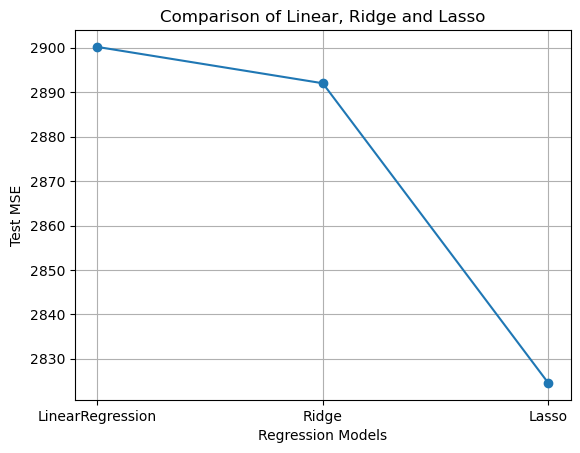

In [19]:
plt.plot(result['Model'], result['Test MSE'], marker='o')

plt.xlabel('Regression Models')
plt.ylabel('Test MSE')
plt.title('Comparison of Linear, Ridge and Lasso')
plt.grid()
plt.show()

In [ ]:
alpha = [0.01, 0.1, 1, 10, 100]

ridge_mse = []
lasso_mse = []

for a in alpha:

    # Ridge
    model = Ridge(alpha=a)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    ridge_mse.append(mean_squared_error(y_test, pred))

    # Lasso
    model = Lasso(alpha=a)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    lasso_mse.append(mean_squared_error(y_test, pred))

# Visualization
plt.plot(alpha, ridge_mse, marker='o', label='Ridge')
plt.plot(alpha, lasso_mse, marker='o', label='Lasso')

plt.xlabel('Alpha')
plt.ylabel('Test MSE')
plt.title('Alpha vs Test MSE')
plt.legend()
plt.grid()
plt.show()